In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.patches import Rectangle, ConnectionPatch
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from mpl_toolkits.axes_grid1.inset_locator import mark_inset
from matplotlib.colors import LinearSegmentedColormap

In [2]:
#parameters plot
def plot_params(fontsize=18, tick_labelsize=12, legend_fontsize=18):
    """
    Update the parameters of the plot.

    Returns
    -------
    cmap : string
        The color map used in the colored plots.
    """
    plt.clf()
    plt.rc('font', size=fontsize)
    plt.rc('xtick', labelsize=tick_labelsize)
    plt.rc('ytick', labelsize=tick_labelsize)
    plt.rc('legend', fontsize=legend_fontsize)
    plt.rc('text', usetex=True)
    font = {'family' : 'stix'}
    plt.rc('font', **font)
    plt.rcParams["mathtext.fontset"] = "stix"
    mpl.rcParams['axes.linewidth'] = 1.3 #set the value globally
    plt.rc('xtick.major', size=8, width=1.3)
    plt.rc('ytick.major', size=8, width=1.3)

In [3]:
#lendo as bifurcacoes
path = "/home/echipicoski/Documents/Projetos/Figuras_Yuri/Fig3/codigos/"

Nci = 20

# ======================================================
# Ler os arquivos
# ======================================================

dfs_bif = []
dfs_est = []

for i in range(1, Nci + 1,1):

    arquivo_bif = f"{path}bif_x_{i}.dat"
    arquivo_est = f"{path}est_x_{i}.dat"

    try:

        df_bif = pd.read_csv(
            arquivo_bif,
            sep=r"\s+",
            header=None,
            names=["b","xmax", "ci", "x0","y0","z0"]
        )

        df_est = pd.read_csv(
            arquivo_est,
            sep=r"\s+",
            header=None,
            names=[
                "ci",
                "b",
                "x0",
                "y0",
                "desvio",
                "media",
                "xmax_est",
                "xmin",
                "amplitude"
            ]
        )

        dfs_bif.append(df_bif)
        dfs_est.append(df_est)

    except FileNotFoundError:
        print(f"Arquivo não encontrado: {i}")

In [4]:
df_bif = pd.concat(dfs_bif, ignore_index=True)
df_est = pd.concat(dfs_est, ignore_index=True)

In [5]:
#bif_x_indo = pd.read_csv("bif_indo_x.dat", sep=r"\s+", header=None, names=["b", "x_max"])
#bif_x_voltando = pd.read_csv("bif_voltando_x.dat", sep=r"\s+", header=None, names=["b", "x_max"])

atrator_laranja = pd.read_csv("/home/echipicoski/Documents/Projetos/Figuras_Yuri/Fig3/atratores/atrator_laranja.dat", 
                              sep=r"\s+", header=None, names=["b", "t", "x","y","z"])
atrator_preto = pd.read_csv("/home/echipicoski/Documents/Projetos/Figuras_Yuri/Fig3/atratores/atrator_preto.dat", 
                              sep=r"\s+", header=None, names=["b", "t", "x","y","z"])
atrator_rosa = pd.read_csv("/home/echipicoski/Documents/Projetos/Figuras_Yuri/Fig3/atratores/atrator_rosa.dat", 
                              sep=r"\s+", header=None, names=["b", "t", "x","y","z"])
atrator_verde = pd.read_csv("/home/echipicoski/Documents/Projetos/Figuras_Yuri/Fig3/atratores/atrator_verde.dat", 
                              sep=r"\s+", header=None, names=["b", "t", "x","y","z"])

NameError: name 'atrator_periodo2' is not defined

<Figure size 640x480 with 0 Axes>

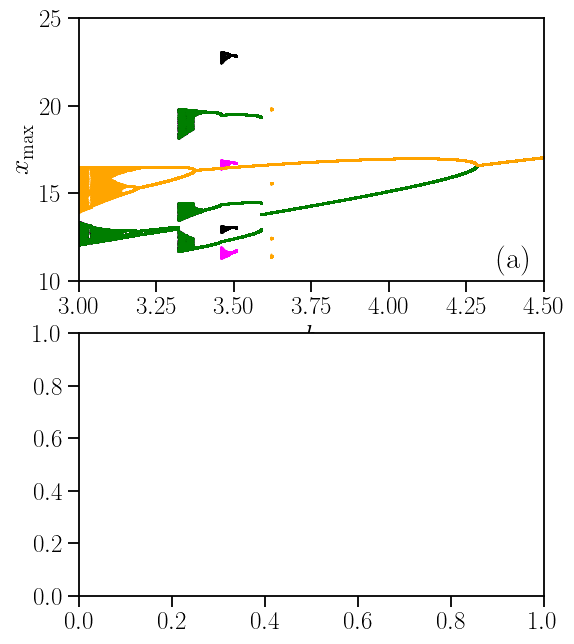

In [11]:
import numpy as np
import matplotlib.pyplot as plt

# ======================================================
# Configurações gerais
# ======================================================

plot_params(
    fontsize=28,
    tick_labelsize=18,
    legend_fontsize=18
)

# ======================================================
# Pasta dos dados
# ======================================================

pasta = (
    "/home/echipicoski/Documents/Projetos/"
    "Figuras_Yuri/Passo_original/"
    "bif_and_basins/csv_multiestabilidade/"
)

# ======================================================
# Arquivos
# ======================================================

arquivos = [
    "periodo2.bin",
    "periodo2'.bin",
    "periodo3.bin",
    "periodo5.bin"
]

# ======================================================
# Cores fixas
# ======================================================

cores = {
    "periodo2.bin": "magenta",
    "periodo2'.bin": "black",
    "periodo3.bin": "green",
    "periodo5.bin": "orange"
}

# ======================================================
# Figura
# ======================================================

fig, ax = plt.subplots(
    2,
    1,
    figsize=(6, 7.5)
)

# ======================================================
# Painel (a)
# Diagrama de bifurcação
# ======================================================

for arquivo in arquivos:

    # --------------------------------------------------
    # Leitura
    # --------------------------------------------------

    caminho = pasta + arquivo

    dados = np.fromfile(
        caminho,
        dtype=np.float64
    )

    dados = dados.reshape(-1, 4)

    # --------------------------------------------------
    # Plot
    # --------------------------------------------------

    ax[0].scatter(
        dados[:, 1],          # b
        dados[:, 3],          # xmax
        s=0.1,
        color=cores[arquivo]
    )

# ------------------------------------------------------
# Limites
# ------------------------------------------------------

ax[0].set_xlim(3.0, 4.5)
ax[0].set_ylim(10, 25)

ax[0].set_yticks(
    [10, 15, 20, 25]
)

# ------------------------------------------------------
# Labels
# ------------------------------------------------------

ax[0].set_xlabel(
    r"$b$",
    fontsize=20
)

ax[0].set_ylabel(
    r"$x_{\max}$",
    fontsize=20
)

# ------------------------------------------------------
# Label (a)
# ------------------------------------------------------

ax[0].text(
    0.9,
    0.05,
    r"(a)",
    transform=ax[0].transAxes,
    fontsize=22,
    fontweight="bold"
)


# ======================================================
# Painel (b)
# Atratores
# ======================================================

# ------------------------------------------------------
# Atrator associado ao periodo2
# ------------------------------------------------------

ax[1].plot(
    atrator_periodo2["x"],
    atrator_periodo2["z"],
    color=cores["periodo2.bin"],
    linewidth=1.0
)

# ------------------------------------------------------
# Atrator associado ao periodo2'
# ------------------------------------------------------

ax[1].plot(
    atrator_periodo2p["x"],
    atrator_periodo2p["z"],
    color=cores["periodo2'.bin"],
    linewidth=1.0
)

# ------------------------------------------------------
# Atrator associado ao periodo3
# ------------------------------------------------------

ax[1].plot(
    atrator_periodo3["x"],
    atrator_periodo3["z"],
    color=cores["periodo3.bin"],
    linewidth=1.0
)

# ------------------------------------------------------
# Atrator associado ao periodo5
# ------------------------------------------------------

ax[1].plot(
    atrator_periodo5["x"],
    atrator_periodo5["z"],
    color=cores["periodo5.bin"],
    linewidth=1.0
)

# ======================================================
# Configurações do painel (b)
# ======================================================

ax[1].set_xlim(
    -20,
    20
)

ax[1].set_ylim(
    20,
    40
)

ax[1].set_xlabel(
    r"$x$",
    fontsize=20
)

ax[1].set_ylabel(
    r"$z$",
    fontsize=20
)

# ------------------------------------------------------
# Label (b)
# ------------------------------------------------------

ax[1].text(
    0.9,
    0.05,
    r"(b)",
    transform=ax[1].transAxes,
    fontsize=22,
    fontweight="bold"
)


# ======================================================
# Ajustes dos ticks
# ======================================================

for a in ax:

    a.tick_params(
        axis="x",
        pad=1
    )

    a.tick_params(
        axis="y",
        pad=1
    )


# ======================================================
# Layout
# ======================================================

plt.tight_layout()


# ======================================================
# Salvar
# ======================================================

plt.savefig(
    "fig3.jpeg",
    format="jpeg",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

<Figure size 640x480 with 0 Axes>

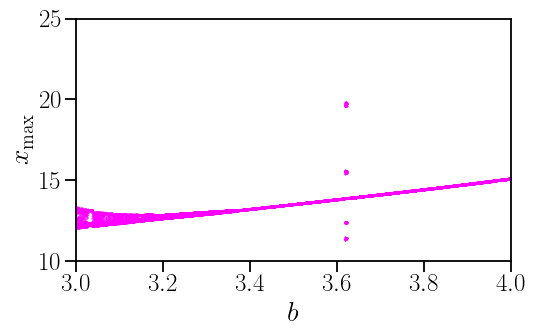

In [12]:
import numpy as np
import matplotlib.pyplot as plt

# ======================================================
# Configurações gerais
# ======================================================

plot_params(
    fontsize=28,
    tick_labelsize=18,
    legend_fontsize=18
)

# ======================================================
# Arquivo
# ======================================================

pasta = (
    "/home/echipicoski/Documents/Projetos/"
    "Figuras_Yuri/Chen-Ueta-main/"
    "bif_and_basins/csv_multiestabilidade/"
)

arquivo = "periodo5.bin"

# ======================================================
# Leitura
# ======================================================

dados = np.fromfile(
    pasta + arquivo,
    dtype=np.float64
)

dados = dados.reshape(-1, 4)

# ======================================================
# Figura
# ======================================================

fig, ax = plt.subplots(
    figsize=(6, 4)
)

# ======================================================
# Diagrama de bifurcação
# ======================================================

ax.scatter(
    dados[:, 1],       # b
    dados[:, 3],       # xmax
    s=0.1,
    color="magenta"
)

# ======================================================
# Limites
# ======================================================

ax.set_xlim(3.0, 4.0)
ax.set_ylim(10, 25)

ax.set_yticks(
    [10, 15, 20, 25]
)

# ======================================================
# Labels
# ======================================================

ax.set_xlabel(
    r"$b$",
    fontsize=20
)

ax.set_ylabel(
    r"$x_{\max}$",
    fontsize=20
)

# ======================================================
# Ticks
# ======================================================

ax.tick_params(
    axis="x",
    pad=1
)

ax.tick_params(
    axis="y",
    pad=1
)

# ======================================================
# Layout
# ======================================================

plt.tight_layout()

# ======================================================
# Salvar
# ======================================================

plt.savefig(
    "bif_periodo2'.jpeg",
    format="jpeg",
    dpi=600,
    bbox_inches="tight"
)

plt.show()